In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [3]:
df=pd.read_csv("https://raw.githubusercontent.com/akmand/datasets/refs/heads/main/california_housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
0,-122.23,37.88,41,880,129.0,322,126,8.3252,NEAR BAY,452600
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,NEAR BAY,358500
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,NEAR BAY,352100
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,NEAR BAY,341300
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,NEAR BAY,342200


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  int64  
 3   total_rooms         20640 non-null  int64  
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  int64  
 6   households          20640 non-null  int64  
 7   median_income       20640 non-null  float64
 8   ocean_proximity     20640 non-null  object 
 9   median_house_value  20640 non-null  int64  
dtypes: float64(4), int64(5), object(1)
memory usage: 1.6+ MB


In [5]:
df.describe(include="all")

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640,20640.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<1H OCEAN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9136,NaN
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,NaN,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,NaN,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,NaN,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,NaN,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,NaN,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,NaN,264725.000000


In [6]:
df.nunique()

longitude               844
latitude                862
housing_median_age       52
total_rooms            5926
total_bedrooms         1923
population             3888
households             1815
median_income         12928
ocean_proximity           5
median_house_value     3842
dtype: int64

In [7]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
ocean_proximity         0
median_house_value      0
dtype: int64

In [8]:
df["total_bedrooms"]=df["total_bedrooms"].fillna(df["total_bedrooms"].median())
df.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
median_house_value    0
dtype: int64

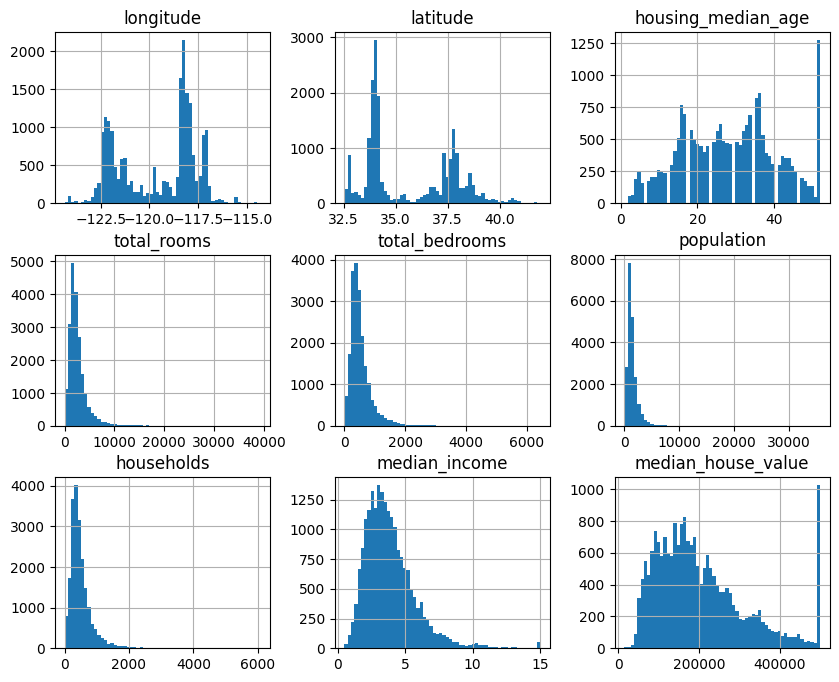

In [9]:
df.hist(bins=60 ,figsize=(10,8))
plt.show()

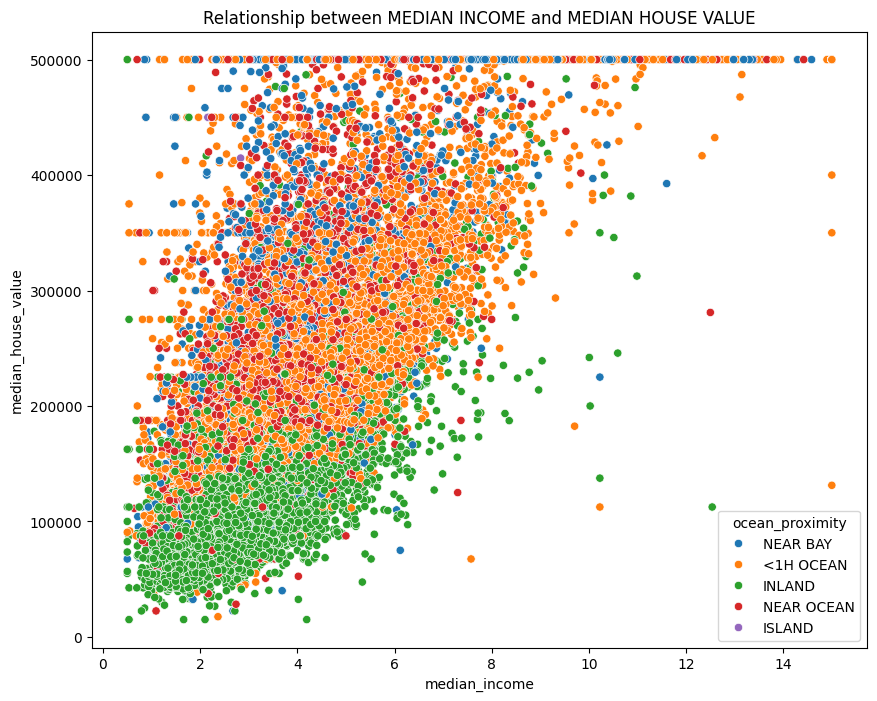

In [10]:
plt.figure(figsize=(10,8))
sns.scatterplot(data=df ,x="median_income" ,y="median_house_value" ,hue="ocean_proximity")
plt.xlabel("median_income")
plt.ylabel("median_house_value")
plt.title("Relationship between MEDIAN INCOME and MEDIAN HOUSE VALUE")
plt.show()

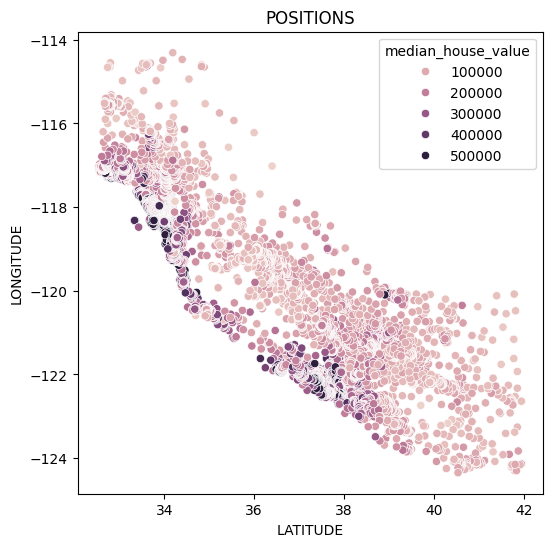

In [11]:
plt.figure(figsize=(6,6))
sns.scatterplot(data=df,x="latitude",y="longitude",hue="median_house_value")
plt.xlabel("LATITUDE")
plt.ylabel("LONGITUDE")
plt.title("POSITIONS")
plt.show()

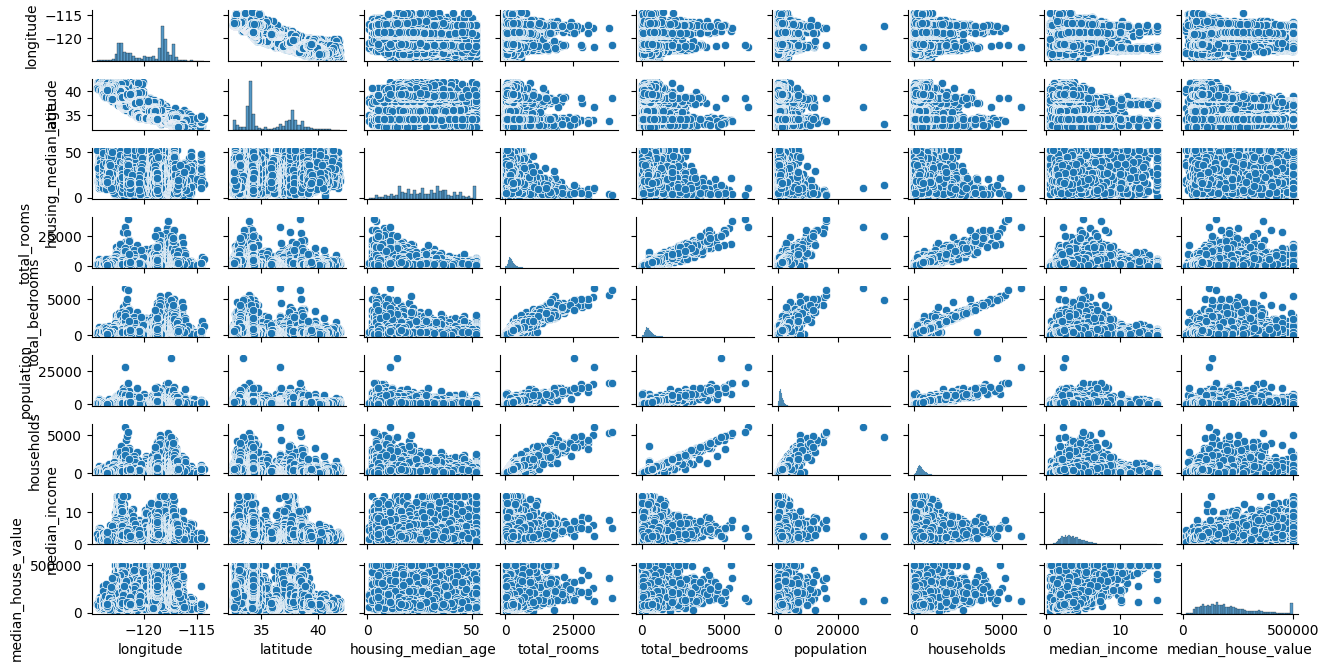

In [12]:
sns.pairplot(df,height=0.75,aspect=2)
plt.show()

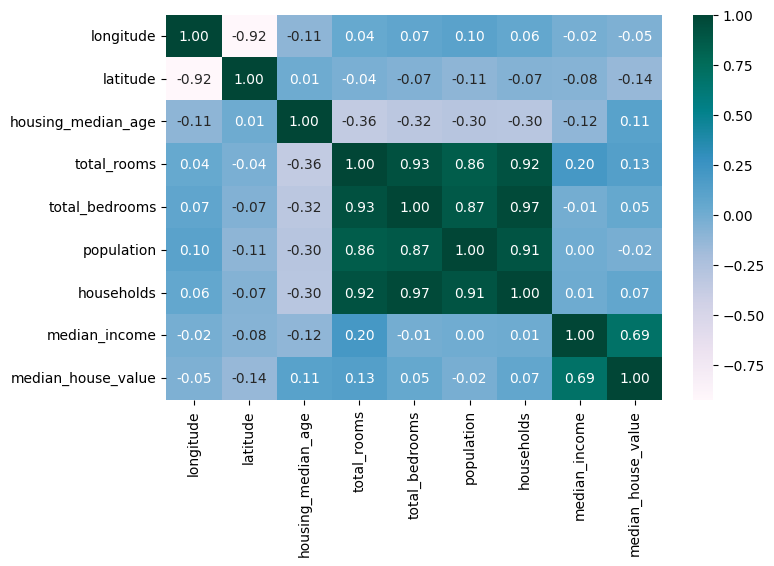

In [13]:
plt.figure(figsize=(8,5))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='PuBuGn',fmt=".2f")
plt.show()

In [14]:
def find_outliers_iqr(df,threshold=1.5):
    outlier_summary={}
    numeric_cols=df.select_dtypes(include=["int32","float32","int64","float64"]).columns

    for col in numeric_cols:
        q1=df[col].quantile(0.25)
        q3=df[col].quantile(0.75)
        iqr=q3-q1
        lower_bound=q1-threshold*iqr
        upper_bound=q3+threshold*iqr
        outliers=df[(df[col]<lower_bound)|(df[col]>upper_bound)]
        outlier_summary[col]={
            "outlier_count":outliers.shape[0],
            "outlier_percentage":100*outliers.shape[0]/df.shape[0],
            "lower_bound":lower_bound,
            "upper_bound":upper_bound
        }
    return pd.DataFrame(outlier_summary)
        

In [15]:
find_outliers_iqr(df,1.5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
outlier_count,0.000,0.00,0.0,1287.000000,1306.000000,1196.000000,1220.000000,681.000000,1071.000000
outlier_percentage,0.000,0.00,0.0,6.235465,6.327519,5.794574,5.910853,3.299419,5.188953
lower_bound,-127.485,28.26,-10.5,-1102.625000,-222.375000,-620.000000,-207.500000,-0.706375,-98087.500000
upper_bound,-112.325,43.38,65.5,5698.375000,1162.625000,3132.000000,1092.500000,8.013025,482412.500000


In [17]:
def remove_outliers_from_all_columns(df,threshold=1.5):
    df_clean=df.copy()
    numeric_col=df.select_dtypes(include=["float64","int64"]).columns
    for col in numeric_col:
        q1=df[col].quantile(0.25)
        q3=df[col].quantile(0.75)
        iqr=q3-q1
        lower_bound=q1-threshold*iqr
        upper_bound=q3+threshold*iqr
        df_clean=df_clean[(df_clean[col]>=lower_bound)&(df_clean[col]<=upper_bound)]
    return df_clean.copy()
df_all_clean=remove_outliers_from_all_columns(df)
print("all columns cleaning shape :" ,df_all_clean.shape)


all columns cleaning shape : (17609, 10)


In [18]:
find_outliers_iqr(df_all_clean,1.5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
outlier_count,0.00,0.00,0.0,318.000000,282.000000,289.000000,269.000000,176.000000,260.000000
outlier_percentage,0.00,0.00,0.0,1.805895,1.601454,1.641206,1.527628,0.999489,1.476518
lower_bound,-127.43,28.24,-9.5,-740.000000,-144.000000,-425.000000,-132.500000,-0.499900,-80300.000000
upper_bound,-112.39,43.44,66.5,4900.000000,1008.000000,2751.000000,943.500000,7.477700,434900.000000


In [19]:
from sklearn.preprocessing import StandardScaler
numerical_cols=df_all_clean.select_dtypes(include=np.number).columns
scaler=StandardScaler()
df_all_clean[numerical_cols]=scaler.fit_transform(df_all_clean[numerical_cols])
display(df_all_clean.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
2,-1.314670,0.994033,1.843602,-0.621751,-1.161059,-1.164096,-1.167652,2.550381,NEAR BAY,1.760119
3,-1.319658,0.994033,1.843602,-0.798766,-0.956359,-1.061235,-0.963098,1.432178,NEAR BAY,1.644942
4,-1.319658,0.994033,1.843602,-0.475004,-0.751658,-1.049622,-0.768285,0.187491,NEAR BAY,1.654540
5,-1.319658,0.994033,1.843602,-1.124362,-1.056435,-1.301797,-1.089727,0.319517,NEAR BAY,0.881356
6,-1.319658,0.989418,1.843602,0.357790,0.199063,-0.171986,0.473648,0.057889,NEAR BAY,1.195962


In [21]:
df_encoded=pd.get_dummies(df_all_clean,columns=['ocean_proximity'])
df_encoded.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
2,-1.314670,0.994033,1.843602,-0.621751,-1.161059,-1.164096,-1.167652,2.550381,1.760119,False,False,False,True,False
3,-1.319658,0.994033,1.843602,-0.798766,-0.956359,-1.061235,-0.963098,1.432178,1.644942,False,False,False,True,False
4,-1.319658,0.994033,1.843602,-0.475004,-0.751658,-1.049622,-0.768285,0.187491,1.654540,False,False,False,True,False
5,-1.319658,0.994033,1.843602,-1.124362,-1.056435,-1.301797,-1.089727,0.319517,0.881356,False,False,False,True,False
6,-1.319658,0.989418,1.843602,0.357790,0.199063,-0.171986,0.473648,0.057889,1.195962,False,False,False,True,False


x_train shape (15848, 13)
y_train shape (15848,)
x_test shape (1761, 13)
y_test shape (1761,)


In [24]:
df_encoded.to_csv("processed.csv",index=False)